In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from lifelines import KaplanMeierFitter, CoxPHFitter

In [9]:
# load the dataset
df = pd.read_csv("student_survival_analysis_dataset.csv")

print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (1000, 10)


,Student_ID,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Time_to_Event_Months,Dropout_Status
0,1,337,118,4,4.5,4.5,9.65,1,30,0
1,2,324,107,4,4.0,4.5,8.87,1,26,0
2,3,316,104,3,3.0,3.5,8.00,1,34,0
3,4,322,110,3,3.5,2.5,8.67,1,11,1
4,5,314,103,2,2.0,3.0,8.21,0,20,1


In [10]:
# Check dataset information
print("Column Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

Column Names:
Index(['Student_ID', 'GRE Score', 'TOEFL Score', 'University Rating', 'SOP',
       'LOR', 'CGPA', 'Research', 'Time_to_Event_Months', 'Dropout_Status'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Student_ID            1000 non-null   int64  
 1   GRE Score             1000 non-null   int64  
 2   TOEFL Score           1000 non-null   int64  
 3   University Rating     1000 non-null   int64  
 4   SOP                   1000 non-null   float64
 5   LOR                   1000 non-null   float64
 6   CGPA                  1000 non-null   float64
 7   Research              1000 non-null   int64  
 8   Time_to_Event_Months  1000 non-null   int64  
 9   Dropout_Status        1000 non-null   int64  
dtypes: float64(3), int64(7)
memory usage: 78.3 KB

Missing Values:
St

In [11]:
print(df["Dropout_Status"].value_counts())

print("\n0 = Retained/Censored")
print("1 = Dropout")

Dropout_Status
0    508
1    492
Name: count, dtype: int64

0 = Retained/Censored
1 = Dropout


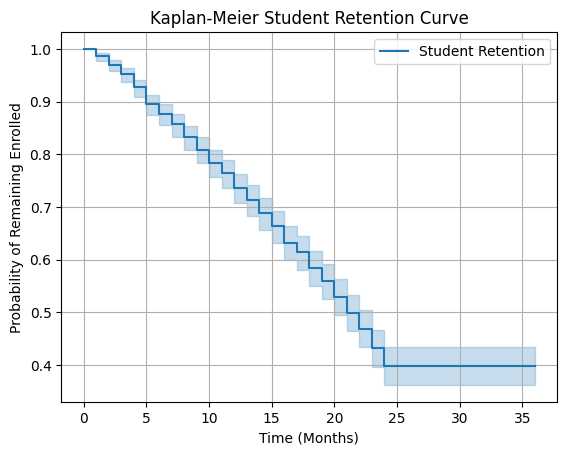

In [12]:
# Perform Kaplan–Meier survival analysis
kmf = KaplanMeierFitter()

kmf.fit(
    durations=df["Time_to_Event_Months"],
    event_observed=df["Dropout_Status"],
    label="Student Retention"
)

kmf.plot_survival_function()

plt.title("Kaplan-Meier Student Retention Curve")
plt.xlabel("Time (Months)")
plt.ylabel("Probability of Remaining Enrolled")
plt.grid(True)
plt.show()

In [13]:
print("Survival Probability at Different Months:")

print(
    kmf.survival_function_at_times([6, 12, 18, 24])
)

Survival Probability at Different Months:
6     0.877000
12    0.736744
18    0.584489
24    0.398519
Name: Student Retention, dtype: float64


In [14]:
#Prepare data for the Cox model
features = [
    "GRE Score",
    "TOEFL Score",
    "University Rating",
    "SOP",
    "LOR",
    "CGPA",
    "Research"
]

duration_col = "Time_to_Event_Months"
event_col = "Dropout_Status"

cox_df = df[
    features + [duration_col, event_col]
].copy()

# Standardize academic features
for col in features:
    std = cox_df[col].std()

    if std > 0:
        cox_df[col] = (
            cox_df[col] - cox_df[col].mean()
        ) / std

cox_df.head()

,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Time_to_Event_Months,Dropout_Status
0,1.567945,1.497981,0.747476,1.077117,1.225860,1.731889,0.993521,30,0
1,0.598927,0.057111,0.747476,0.590394,1.225860,0.457733,0.993521,26,0
2,0.002609,-0.335854,-0.011383,-0.383051,0.104612,-0.963442,0.993521,34,0
3,0.449848,0.450075,-0.011383,0.103672,-1.016635,0.131026,0.993521,11,1
4,-0.146471,-0.466842,-0.770242,-1.356496,-0.456011,-0.620400,-1.005515,20,1


In [15]:
# train the Cox Proportional Hazards model
cph = CoxPHFitter()

cph.fit(
    cox_df,
    duration_col=duration_col,
    event_col=event_col
)

cph.print_summary()

<lifelines.CoxPHFitter: fitted with 1000 total observations, 508 right-censored observations>
             duration col = 'Time_to_Event_Months'
                event col = 'Dropout_Status'
      baseline estimation = breslow
   number of observations = 1000
number of events observed = 492
   partial log-likelihood = -3062.62
         time fit was run = 2026-10-15 09:21:50 UTC

---
                   coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                          
GRE Score         -0.33      0.72      0.05           -0.42           -0.23                0.66                0.79
TOEFL Score       -0.26      0.77      0.05           -0.36           -0.17                0.70                0.84
University Rating  0.07      1.07      0.05           -0.02            0.16                0.98                1.18
SOP                0.14      1.16      0.05            0.05            0.24                1.05                1.27
LOR               -0.14      0.87      0.05           -0.23           -0.04                0.79                0.96
CGPA              -0.22      0.80      0.05           -0.32           -0.12                0.73                0.88
Research           0.02      1.02      0.05           -0.07            0.11                0.93                1.12

                   cmp to     z      p  -log2(p)
covariate                                       
GRE Score            0.00 -6.78 <0.005     36.28
TOEFL Score          0.00 -5.63 <0.005     25.75
University Rating    0.00  1.49   0.14      2.88
SOP                  0.00  3.01 <0.005      8.57
LOR                  0.00 -2.76   0.01      7.45
CGPA                 0.00 -4.44 <0.005     16.76
Research             0.00  0.41   0.68      0.55
---
Concordance = 0.66
Partial AIC = 6139.24
log-likelihood ratio test = 155.23 on 7 df
-log2(p) of ll-ratio test = 97.96

In [16]:
#Predict student dropout risk
df["Relative_Dropout_Risk"] = (
    cph.predict_partial_hazard(cox_df[features])
    .values
)

cutoff = df["Relative_Dropout_Risk"].median()

df["Risk_Group"] = np.where(
    df["Relative_Dropout_Risk"] >= cutoff,
    "Higher Risk",
    "Lower Risk"
)

df[
    [
        "Student_ID",
        "Time_to_Event_Months",
        "Dropout_Status",
        "Relative_Dropout_Risk",
        "Risk_Group"
    ]
].head(10)

,Student_ID,Time_to_Event_Months,Dropout_Status,Relative_Dropout_Risk,Risk_Group
0,1,30,0,0.292815,Lower Risk
1,2,26,0,0.724794,Lower Risk
2,3,34,0,1.281070,Higher Risk
3,4,11,1,0.885385,Lower Risk
4,5,20,1,1.104845,Higher Risk
5,6,4,1,0.572390,Lower Risk
6,7,11,1,0.822191,Lower Risk
7,8,19,0,1.511119,Higher Risk
8,9,19,1,1.971348,Higher Risk
9,10,31,0,0.846143,Lower Risk


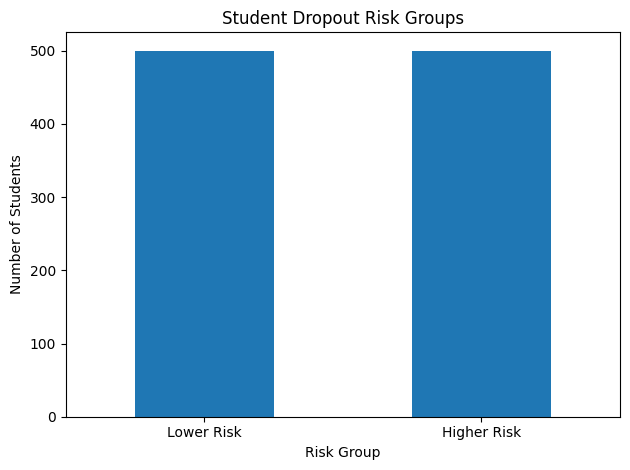

In [17]:
df["Risk_Group"].value_counts().plot(
    kind="bar",
    title="Student Dropout Risk Groups"
)

plt.xlabel("Risk Group")
plt.ylabel("Number of Students")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [18]:
df.to_csv(
    "student_survival_risk_predictions.csv",
    index=False
)

print("Student survival analysis completed!")
print("Predictions saved successfully.")

Student survival analysis completed!
Predictions saved successfully.
